<a href="https://colab.research.google.com/github/ust-buan-640/buan-640-notebooks/blob/main/notebooks/reg-1-predicting-a-price.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting a home's price

In [ ]:
# Setup: libraries, colors, plotting helpers, and the North Ames data
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Rectangle, FancyBboxPatch
import scipy.stats as stats
import statsmodels.formula.api as smf


PURPLE, GOLD, GRAY, LIGHT, SAND = "#510C76", "#B07A00", "#6E6E6E", "#C9B8D6", "#EFE3C2"
plt.rcParams.update({"font.size": 14, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#444444", "axes.labelcolor": "#222222",
                     "xtick.color": "#444444", "ytick.color": "#444444",
                     "axes.titlesize": 14, "legend.fontsize": 12})
DOLLARS = mtick.FuncFormatter(lambda v, p: "$0" if v == 0 else ("−" if v < 0 else "") + f"${abs(v)/1000:,.0f}K")


def fit(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
    return y.mean() - b1 * x.mean(), b1


def home_axes(ax, xlim=(700, 2400), ylim=(0, 290000)):
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.yaxis.set_major_formatter(DOLLARS)
    ax.set_xlabel("living area (sq ft)"); ax.set_ylabel("sale price")


na = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/north_ames_2007.csv")
x, y = na.area.values.astype(float), na.price.values.astype(float)
n = len(na)
b0, b1 = fit(x, y)
yhat = b0 + b1 * x
res = y - yhat
s = np.sqrt(np.sum(res ** 2) / (n - 2))
xbar, ybar = x.mean(), y.mean()
ssxx = np.sum((x - xbar) ** 2)
XS = np.linspace(700, 2400, 100)

# a fixed subset of 15 homes for the pictures with error segments
rng = np.random.default_rng(640)
sub = na.iloc[np.sort(rng.choice(n, 15, replace=False))]
xs_, ys_ = sub.area.values.astype(float), sub.price.values.astype(float)
a_s, b_s = fit(xs_, ys_)


def box(ax, cx, cy, w, h, text, ec=PURPLE, fc="white", fs=13):
    ax.add_patch(FancyBboxPatch((cx - w / 2, cy - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=fc, ec=ec, lw=1.6))
    ax.text(cx, cy, text, ha="center", va="center", fontsize=fs)
def arrow(ax, p, q, color=PURPLE):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6))

plt.rcParams["figure.dpi"] = 110

You are pricing a home, as an appraiser, an agent, or a buyer. Sale prices of the 89 single-family homes sold in North Ames, Iowa, in 2007 range from about \$99,000 to \$268,000. What explains that spread? The first thing most people look at is size.

*Data: Ames housing data (De Cock, 2011, Journal of Statistics Education), single-family homes in the North Ames neighborhood sold under normal conditions in 2007, n = 89. Living area is the finished area above ground, in square feet; basements are not included.*

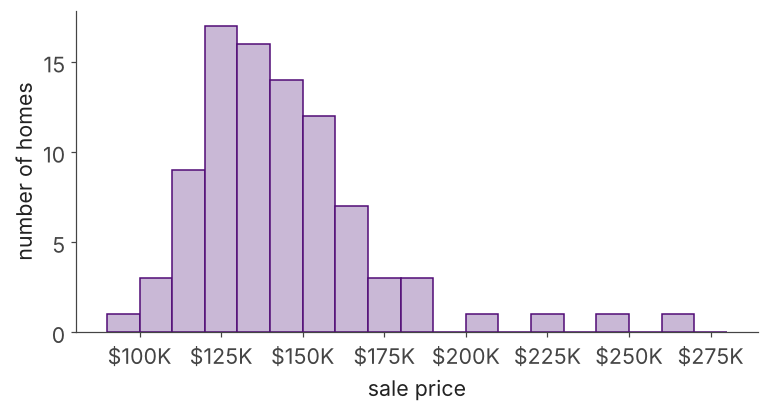

In [ ]:
# ---------------- 1. predicting a price ----------------
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(y, bins=np.arange(90000, 280001, 10000), color=LIGHT, edgecolor=PURPLE)
ax.xaxis.set_major_formatter(DOLLARS); ax.set_xlabel("sale price"); ax.set_ylabel("number of homes")
plt.show()  # f01_price_hist.png

## Bigger homes, higher prices

Each dot is one home. Larger homes tend to sell for more, but homes of the same size sell for quite different prices. Notice the two large homes at the top right; we will see them again.

We use one neighborhood and one year on purpose. Why that matters comes up when we talk about the assumptions behind regression.

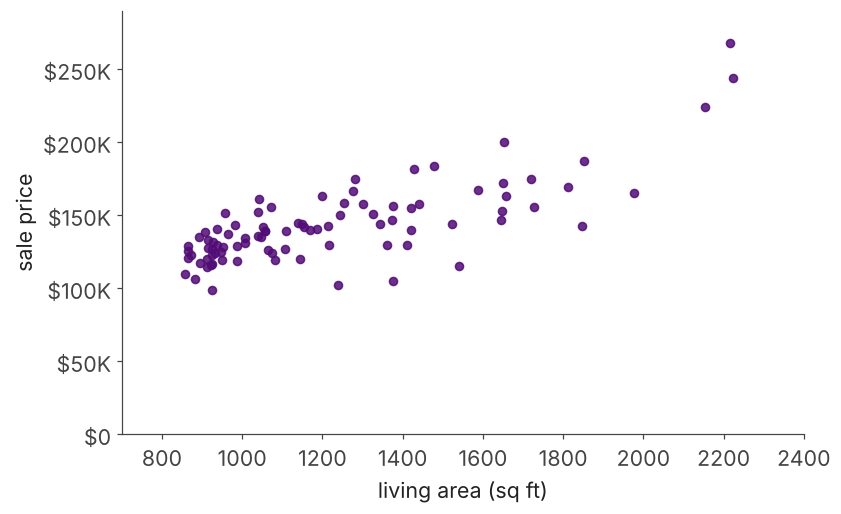

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, color=PURPLE, s=28, alpha=0.85)
home_axes(ax)
plt.show()  # f02_scatter.png

## A line, plus or minus something

The plan is to describe the pattern with a line and accept that individual homes scatter around it:

$$\text{price} = a + b \times \text{area}, \quad \text{plus or minus a prediction error}$$

We want two things from the data: the line, and how far homes typically fall from it.

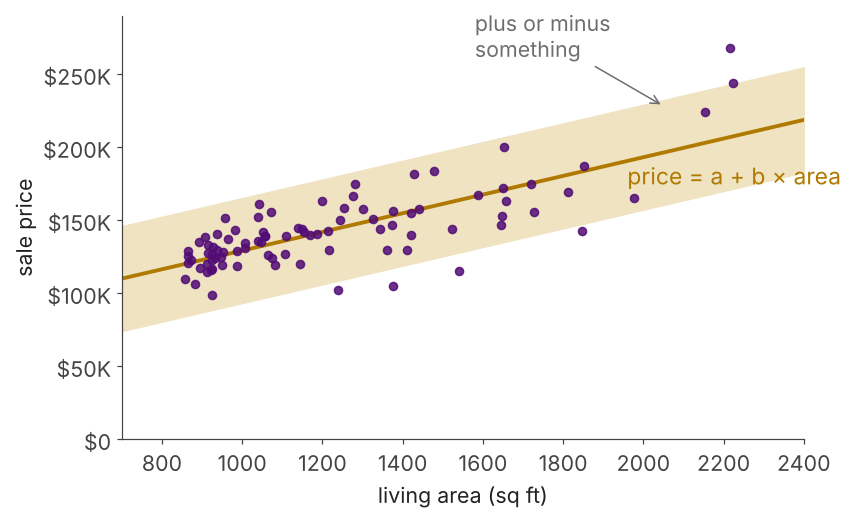

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(XS, b0 + b1 * XS - 2 * s, b0 + b1 * XS + 2 * s, color=SAND)
ax.plot(XS, b0 + b1 * XS, color=GOLD, lw=2.5)
ax.scatter(x, y, color=PURPLE, s=28, alpha=0.85, zorder=3)
ax.text(1960, b0 + b1 * 1960 - 16000, "price = a + b × area", color=GOLD, fontsize=15, ha="left")
ax.annotate("plus or minus\nsomething", xy=(2050, b0 + b1 * 2050 + 2 * s - 4000), xytext=(1580, 262000),
            fontsize=14, color=GRAY, arrowprops=dict(arrowstyle="->", color=GRAY))
home_axes(ax)
plt.show()  # f03_model_band.png

## Why not just price per square foot?

Price per square foot is what people quote. Using it means a line through zero: price $= k \times$ area.

The left panel shows that larger homes sell for less per square foot, so one $k$ cannot fit all sizes. On the right, the line through zero overprices big homes and underprices small ones.

Part of a home's price does not grow with size: the lot, the location, the kitchen, the furnace. The intercept $a$ absorbs that part. The slope $b$ then measures what one more square foot adds, which is less than the average price per square foot.

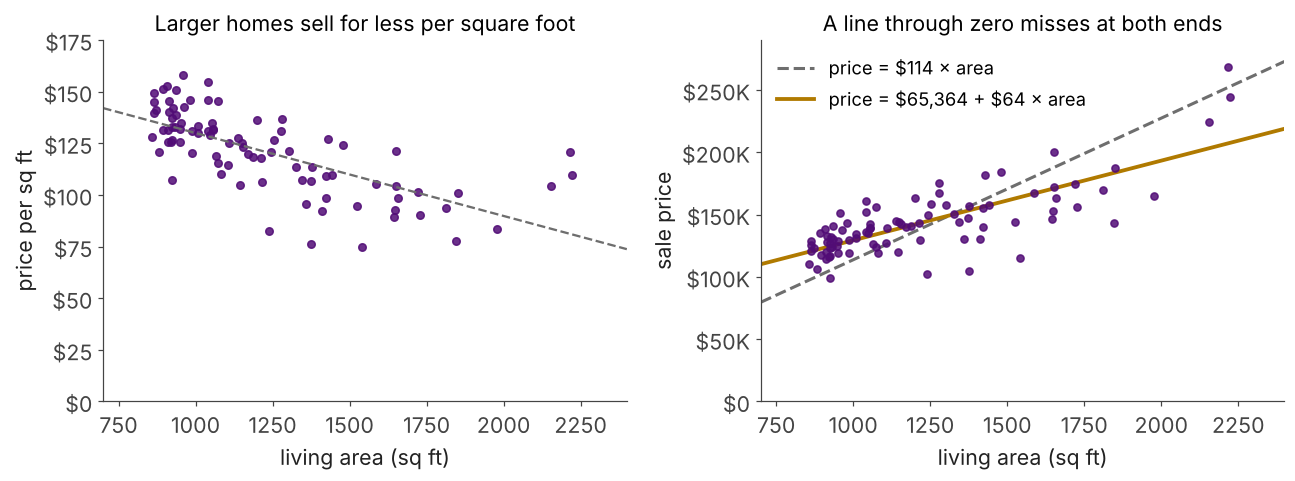

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
axs[0].scatter(x, y / x, color=PURPLE, s=24, alpha=0.85)
a_pp, b_pp = fit(x, y / x)
axs[0].plot(XS, a_pp + b_pp * XS, color=GRAY, lw=1.5, ls="--")
axs[0].set_xlim(700, 2400); axs[0].set_ylim(0, 175); axs[0].set_xlabel("living area (sq ft)"); axs[0].set_ylabel("price per sq ft")
axs[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
axs[0].set_title("Larger homes sell for less per square foot")
k0 = np.sum(x * y) / np.sum(x * x)       # least squares line through the origin
axs[1].scatter(x, y, color=PURPLE, s=22, alpha=0.85, zorder=3)
axs[1].plot(XS, k0 * XS, color=GRAY, lw=2, ls="--", label=f"price = \\${k0:,.0f} × area")
axs[1].plot(XS, b0 + b1 * XS, color=GOLD, lw=2.5, label=f"price = \\${b0:,.0f} + \\${b1:,.0f} × area")
home_axes(axs[1]); axs[1].legend(frameon=False, loc="upper left")
axs[1].set_title("A line through zero misses at both ends")
fig.tight_layout(); plt.show()  # f04_price_per_sqft.png

## Deterministic and statistical models

A deterministic model says that price follows exactly from size. Real prices do not. A statistical model has a deterministic part, the line, plus a random error $\varepsilon$ that stands for everything else that affects price: condition, lot, layout, the seller's situation, and chance.

All models are wrong, but some are useful (George Box).

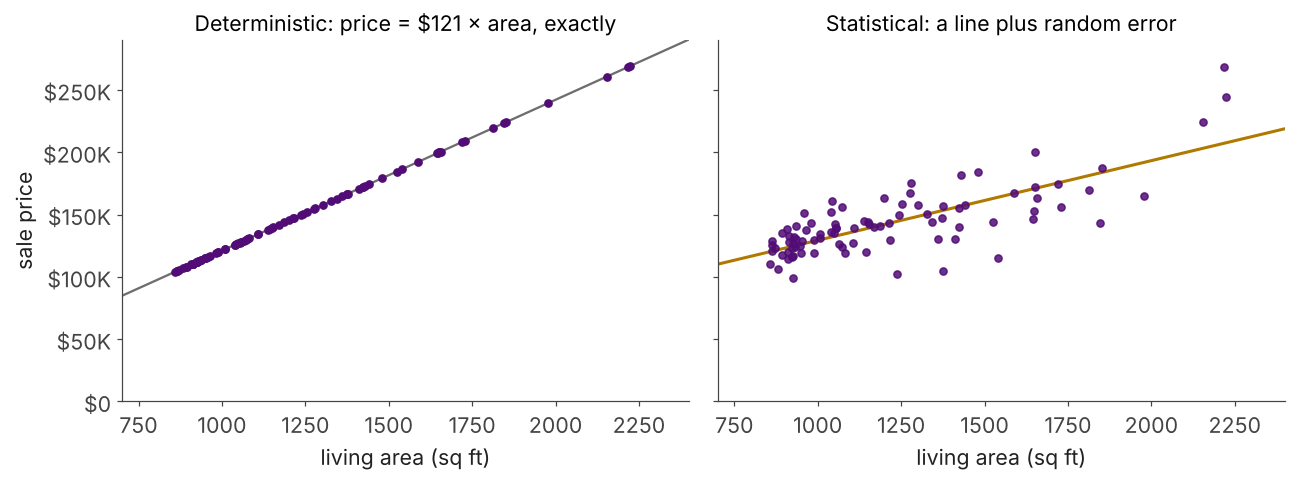

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
avg_pp = np.mean(y / x)
axs[0].plot(XS, avg_pp * XS, color=GRAY, lw=1.5)
axs[0].scatter(x, avg_pp * x, color=PURPLE, s=22, zorder=3)
axs[0].set_title(f"Deterministic: price = ${avg_pp:,.0f} × area, exactly")
axs[1].plot(XS, b0 + b1 * XS, color=GOLD, lw=2)
axs[1].scatter(x, y, color=PURPLE, s=22, alpha=0.85, zorder=3)
axs[1].set_title("Statistical: a line plus random error")
for ax in axs: home_axes(ax)
axs[1].set_ylabel("")
fig.tight_layout(); plt.show()  # f05_det_vs_stat.png

## The parts of the model

$$y = \beta_0 + \beta_1 x + \varepsilon$$

- $y$ is the **dependent variable**, the one we want to predict: sale price.
- $x$ is the **independent variable**, the one we predict from: living area.
- $\beta_0$ (intercept) and $\beta_1$ (slope) describe the population line. Like $\mu$, they are unknown, and we estimate them from a sample.
- $\varepsilon$ is the random error.

"Independent variable" here only means the variable on the x-axis. It has nothing to do with statistical independence.

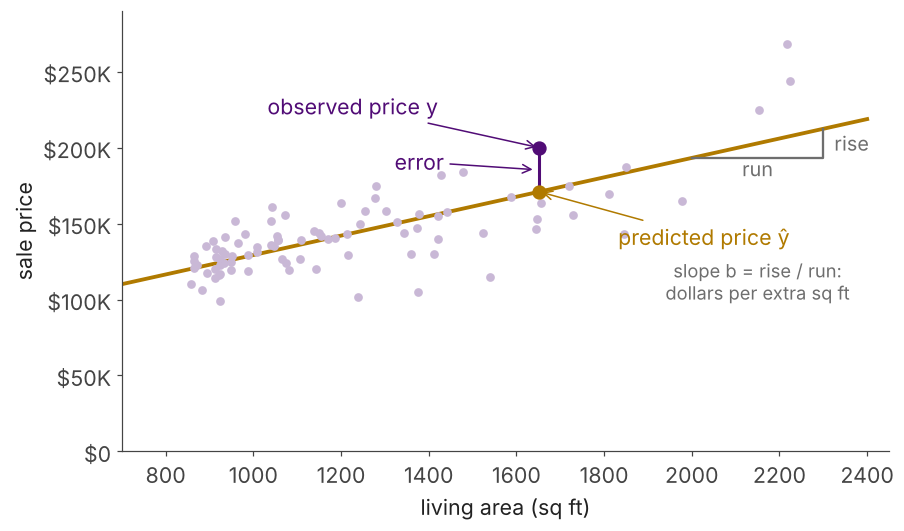

In [ ]:
# anatomy of the model
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.plot(XS, b0 + b1 * XS, color=GOLD, lw=2.5)
ax.scatter(x, y, color=LIGHT, s=22, zorder=2)
i = int(np.argmax(res * (x > 1300) * (x < 1700)))
xi, yi, yhi = x[i], y[i], yhat[i]
ax.scatter([xi], [yi], color=PURPLE, s=70, zorder=4)
ax.scatter([xi], [yhi], color=GOLD, s=70, zorder=4)
ax.plot([xi, xi], [yhi, yi], color=PURPLE, lw=2)
ax.annotate("observed price y", xy=(xi, yi), xytext=(xi - 620, yi + 22000), color=PURPLE,
            arrowprops=dict(arrowstyle="->", color=PURPLE))
ax.annotate("predicted price ŷ", xy=(xi, yhi), xytext=(xi + 180, yhi - 35000), color=GOLD,
            arrowprops=dict(arrowstyle="->", color=GOLD))
ax.annotate("error", xy=(xi - 8, (yi + yhi) / 2), xytext=(xi - 330, (yi + yhi) / 2), color=PURPLE,
            arrowprops=dict(arrowstyle="->", color=PURPLE))
x1, x2 = 2000, 2300
ax.plot([x1, x2, x2], [b0 + b1 * x1, b0 + b1 * x1, b0 + b1 * x2], color=GRAY, lw=1.5)
ax.text((x1 + x2) / 2, b0 + b1 * x1 - 12000, "run", ha="center", color=GRAY, fontsize=13)
ax.text(x2 + 25, b0 + b1 * (x1 + x2) / 2, "rise", color=GRAY, fontsize=13, va="center")
ax.text(2150, 100000, "slope b = rise / run:\ndollars per extra sq ft", ha="center", color=GRAY, fontsize=12)
home_axes(ax, xlim=(700, 2450))
plt.show()  # f06_anatomy.png